In [ ]:
                   ## Brazilian Ecommerce Market Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [19]:
Customer = pd.read_csv("Customer.csv")
Geolocation = pd.read_csv("geolocation.csv")
Order_items = pd.read_csv("order_items.csv")
Order_Payment = pd.read_csv("order_payments.csv")
Order_reviews = pd.read_csv("order_reviews.csv")
Orders = pd.read_csv("orders.csv")
Product_category_name_translation = pd.read_csv("product_category_name_translation.csv")
Products = pd.read_csv("products.csv")
Sellers = pd.read_csv("sellers.csv")

In [20]:
print("Customers:", Customer.shape)
print("Geolocation:", Geolocation.shape)
print("Order Items:", Order_items.shape)
print("Payments:", Order_Payment.shape)
print("Reviews:", Order_reviews.shape)
print("Orders:", Orders.shape)
print("Category Translation:", Product_category_name_translation.shape)
print("Products:", Products.shape)
print("Sellers:", Sellers.shape)

Customers: (99441, 5)
Geolocation: (1000163, 5)
Order Items: (112650, 7)
Payments: (103886, 5)
Reviews: (99224, 7)
Orders: (99441, 8)
Category Translation: (71, 2)
Products: (32951, 9)
Sellers: (3095, 4)


In [21]:
# Store all nine DataFrames in a dictionary.
# Each key identifies a dataset, and its value is the corresponding DataFrame.

datasets = {
    "Customer": Customer,
    "Geolocation": Geolocation,
    "Order_Items": Order_items,
    "Order_Payment": Order_Payment,
    "Order_Reviews": Order_reviews,
    "Orders": Orders,
    "Category_Translation": Product_category_name_translation,
    "Products": Products,
    "Sellers": Sellers
}

# Confirm the number of datasets available for analysis
print("Total datasets loaded:", len(datasets))

Total datasets loaded: 9


In [22]:
# Display the number of rows and columns in each dataset

print("DATASET DIMENSIONS")
print("=" * 60)

for name, df in datasets.items():

    # Extract the number of rows and columns
    rows, columns = df.shape

    # Display the dataset name and its dimensions
    print(f"{name}: {rows:,} rows and {columns} columns")

DATASET DIMENSIONS
Customer: 99,441 rows and 5 columns
Geolocation: 1,000,163 rows and 5 columns
Order_Items: 112,650 rows and 7 columns
Order_Payment: 103,886 rows and 5 columns
Order_Reviews: 99,224 rows and 7 columns
Orders: 99,441 rows and 8 columns
Category_Translation: 71 rows and 2 columns
Products: 32,951 rows and 9 columns
Sellers: 3,095 rows and 4 columns


In [23]:
# Display the first five records from every dataset

for name, df in datasets.items():

    print(f"\n{'=' * 70}")
    print(f"DATASET: {name}")
    print("=" * 70)

    # Display the first five rows
    display(df.head())


DATASET: Customer


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



DATASET: Geolocation


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



DATASET: Order_Items


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,9/19/2017 9:45,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,5/3/2017 11:05,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,1/18/2018 14:48,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,8/15/2018 10:10,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2/13/2017 13:57,199.90,18.14


... (8 outputs left out)


DATASET: Products


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0



DATASET: Sellers


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [24]:
# Display all column names for each dataset

for name, df in datasets.items():

    print(f"\nDataset: {name}")
    print("-" * 60)

    # Print the column names
    for column in df.columns:
        print(column)


Dataset: Customer
------------------------------------------------------------
customer_id
customer_unique_id
customer_zip_code_prefix
customer_city
customer_state

Dataset: Geolocation
------------------------------------------------------------
geolocation_zip_code_prefix
geolocation_lat
geolocation_lng
geolocation_city
geolocation_state

Dataset: Order_Items
------------------------------------------------------------
order_id
order_item_id
product_id
seller_id
shipping_limit_date
price
freight_value

Dataset: Order_Payment
------------------------------------------------------------
order_id
payment_sequential
payment_type
payment_installments
payment_value

Dataset: Order_Reviews
------------------------------------------------------------
review_id
order_id
review_score
review_comment_title
review_comment_message
review_creation_date
review_answer_timestamp

Dataset: Orders
------------------------------------------------------------
order_id
customer_id
order_status
order_purch

In [25]:
# Examine the structure and data types of every dataset

for name, df in datasets.items():

    print(f"\n{'=' * 70}")
    print(f"DATASET: {name}")
    print("=" * 70)

    # Display column names, data types, non-null counts, and memory usage
    df.info()


DATASET: Customer
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

DATASET: Geolocation
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geoloc

In [26]:
# Generate descriptive statistics for each dataset

for name, df in datasets.items():

    print(f"\n{'=' * 70}")
    print(f"DESCRIPTIVE STATISTICS: {name}")
    print("=" * 70)

    # Summarise numerical and non-numerical columns
    display(df.describe(include="all").T)


DESCRIPTIVE STATISTICS: Customer


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,99441,99441,274fa6071e5e17fe303b9748641082c8,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_unique_id,99441,96096,8d50f5eadf50201ccdcedfb9e2ac8455,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_zip_code_prefix,99441.0,NaN,NaN,NaN,35137.474583,29797.938996,1003.0,11347.0,24416.0,58900.0,99990.0
customer_city,99441,4119,sao paulo,15540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,99441,27,SP,41746,NaN,NaN,NaN,NaN,NaN,NaN,NaN



DESCRIPTIVE STATISTICS: Geolocation


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,1000163.0,NaN,NaN,NaN,36574.166466,30549.33571,1001.0,11075.0,26530.0,63504.0,99990.0
geolocation_lat,1000163.0,NaN,NaN,NaN,-21.176153,5.715866,-36.605374,-23.603546,-22.919377,-19.97962,45.065933
geolocation_lng,1000163.0,NaN,NaN,NaN,-46.390541,4.269748,-101.466766,-48.573172,-46.637879,-43.767709,121.105394
geolocation_city,1000163,8011,sao paulo,135800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geolocation_state,1000163,27,SP,404268,NaN,NaN,NaN,NaN,NaN,NaN,NaN



DESCRIPTIVE STATISTICS: Order_Items


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,112650,98666,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_item_id,112650.0,NaN,NaN,NaN,1.197834,0.705124,1.0,1.0,1.0,1.0,21.0
product_id,112650,32951,aca2eb7d00ea1a7b8ebd4e68314663af,527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_id,112650,3095,6560211a19b47992c3666cc44a7e94c0,2033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_limit_date,112650,54615,4/23/2018 5:50,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,112650.0,NaN,NaN,NaN,120.653739,183.633928,0.85,39.9,74.99,134.9,6735.0
freight_value,112650.0,NaN,NaN,NaN,19.99032,15.806405,0.0,13.08,16.26,21.15,409.68


... (8 outputs left out)


DESCRIPTIVE STATISTICS: Products


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,32951,32951,106392145fca363410d287a815be6de4,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,32341,73,cama_mesa_banho,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name_lenght,32341.0,NaN,NaN,NaN,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,NaN,NaN,NaN,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,NaN,NaN,NaN,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,NaN,NaN,NaN,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,NaN,NaN,NaN,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,NaN,NaN,NaN,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,NaN,NaN,NaN,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0



DESCRIPTIVE STATISTICS: Sellers


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
seller_id,3095,3095,9e25199f6ef7e7c347120ff175652c3b,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_zip_code_prefix,3095.0,NaN,NaN,NaN,32291.059451,32713.45383,1001.0,7093.5,14940.0,64552.5,99730.0
seller_city,3095,611,sao paulo,694,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_state,3095,23,SP,1849,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
# Count missing values in every column of every dataset

for name, df in datasets.items():

    print(f"\n{'=' * 70}")
    print(f"MISSING VALUES: {name}")
    print("=" * 70)

    # Count missing values in each column
    missing_counts = df.isnull().sum()

    # Calculate the percentage of missing values in each column
    missing_percentage = (missing_counts / len(df)) * 100

    # Combine both results into a summary table
    missing_summary = pd.DataFrame({
        "Missing_Count": missing_counts,
        "Missing_Percentage": missing_percentage.round(2)
    })

    # Display only columns that contain missing values
    display(missing_summary[missing_summary["Missing_Count"] > 0])


MISSING VALUES: Customer


,Missing_Count,Missing_Percentage



MISSING VALUES: Geolocation


,Missing_Count,Missing_Percentage



MISSING VALUES: Order_Items


,Missing_Count,Missing_Percentage


... (8 outputs left out)


MISSING VALUES: Products


,Missing_Count,Missing_Percentage
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01



MISSING VALUES: Sellers


,Missing_Count,Missing_Percentage


In [28]:
# Count fully duplicated rows in each dataset

for name, df in datasets.items():

    # Count rows that exactly duplicate a preceding row
    duplicate_count = df.duplicated().sum()

    # Calculate the percentage of duplicated rows
    duplicate_percentage = (
        duplicate_count / len(df) * 100
        if len(df) > 0 else 0
    )

    print(f"\nDataset: {name}")
    print(f"Duplicate rows: {duplicate_count:,}")
    print(f"Duplicate percentage: {duplicate_percentage:.2f}%")


Dataset: Customer
Duplicate rows: 0
Duplicate percentage: 0.00%

Dataset: Geolocation
Duplicate rows: 261,836
Duplicate percentage: 26.18%

Dataset: Order_Items
Duplicate rows: 0
Duplicate percentage: 0.00%

Dataset: Order_Payment
Duplicate rows: 0
Duplicate percentage: 0.00%

Dataset: Order_Reviews
Duplicate rows: 0
Duplicate percentage: 0.00%

Dataset: Orders
Duplicate rows: 0
Duplicate percentage: 0.00%

Dataset: Category_Translation
Duplicate rows: 0
Duplicate percentage: 0.00%

Dataset: Products
Duplicate rows: 0
Duplicate percentage: 0.00%

Dataset: Sellers
Duplicate rows: 0
Duplicate percentage: 0.00%


In [29]:
# Create an overview table for the entire project

dataset_summary = []

for name, df in datasets.items():

    # Calculate the number of rows and columns
    rows, columns = df.shape

    # Count the total missing values
    missing_values = df.isnull().sum().sum()

    # Count fully duplicated rows
    duplicate_rows = df.duplicated().sum()

    # Store the summary for this dataset
    dataset_summary.append({
        "Dataset": name,
        "Rows": rows,
        "Columns": columns,
        "Missing_Values": missing_values,
        "Duplicate_Rows": duplicate_rows,
        "Memory_MB": round(
            df.memory_usage(deep=True).sum() / (1024 ** 2), 2
        )
    })

# Convert the summary into a DataFrame
dataset_overview = pd.DataFrame(dataset_summary)

# Display the completed overview
display(dataset_overview)

,Dataset,Rows,Columns,Missing_Values,Duplicate_Rows,Memory_MB
0,Customer,99441,5,0,0,26.59
1,Geolocation,1000163,5,0,261836,130.26
2,Order_Items,112650,7,0,0,35.52
3,Order_Payment,103886,5,0,0,16.23
4,Order_Reviews,99224,7,145903,0,38.23
5,Orders,99441,8,4908,0,50.85
6,Category_Translation,71,2,0,0,0.01
7,Products,32951,9,2448,0,6.30
8,Sellers,3095,4,0,0,0.59


In [ ]:
      # Data Quality Assessment & Cleaning

In [30]:
# SET 2 — STEP 1: MISSING-VALUE ASSESSMENT

# Check missing values in every dataset
for name, df in datasets.items():

    print(f"\n{'=' * 60}")
    print(f"DATASET: {name}")
    print(f"{'=' * 60}")

    # Count missing values in each column
    missing_count = df.isnull().sum()

    # Calculate missing-value percentage for each column
    missing_percentage = (missing_count / len(df)) * 100

    # Combine the results into a summary table
    missing_summary = pd.DataFrame({
        "Missing_Count": missing_count,
        "Missing_Percentage": missing_percentage.round(2)
    })

    # Display only columns containing missing values
    missing_summary = missing_summary[
        missing_summary["Missing_Count"] > 0
    ]

    if missing_summary.empty:
        print("No missing values found.")
    else:
        display(missing_summary.sort_values(
            by="Missing_Count",
            ascending=False
        ))


DATASET: Customer
No missing values found.

DATASET: Geolocation
No missing values found.

DATASET: Order_Items
No missing values found.

DATASET: Order_Payment
No missing values found.

DATASET: Order_Reviews


,Missing_Count,Missing_Percentage
review_comment_title,87656,88.34
review_comment_message,58247,58.70



DATASET: Orders


,Missing_Count,Missing_Percentage
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16



DATASET: Category_Translation
No missing values found.

DATASET: Products


,Missing_Count,Missing_Percentage
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01



DATASET: Sellers
No missing values found.


In [31]:
# Identify columns with 5% or more missing values

missing_threshold = 5

for name, df in datasets.items():

    # Calculate missing percentage for each column
    missing_percentage = (df.isnull().sum() / len(df)) * 100

    # Select columns meeting the threshold
    high_missing = missing_percentage[
        missing_percentage >= missing_threshold
    ].sort_values(ascending=False)

    print(f"\nDataset: {name}")

    if high_missing.empty:
        print("No columns have 5% or more missing values.")
    else:
        display(
            high_missing.round(2).rename(
                "Missing_Percentage"
            ).to_frame()
        )


Dataset: Customer
No columns have 5% or more missing values.

Dataset: Geolocation
No columns have 5% or more missing values.

Dataset: Order_Items
No columns have 5% or more missing values.

Dataset: Order_Payment
No columns have 5% or more missing values.

Dataset: Order_Reviews


,Missing_Percentage
review_comment_title,88.34
review_comment_message,58.70



Dataset: Orders
No columns have 5% or more missing values.

Dataset: Category_Translation
No columns have 5% or more missing values.

Dataset: Products
No columns have 5% or more missing values.

Dataset: Sellers
No columns have 5% or more missing values.


In [32]:
# Check completely duplicated rows in every dataset

for name, df in datasets.items():

    duplicate_count = df.duplicated().sum()

    print(f"{name}: {duplicate_count} completely duplicated rows")

Customer: 0 completely duplicated rows
Geolocation: 261836 completely duplicated rows
Order_Items: 0 completely duplicated rows
Order_Payment: 0 completely duplicated rows
Order_Reviews: 0 completely duplicated rows
Orders: 0 completely duplicated rows
Category_Translation: 0 completely duplicated rows
Products: 0 completely duplicated rows
Sellers: 0 completely duplicated rows


In [33]:
# Display duplicate rows for inspection

for name, df in datasets.items():

    duplicate_rows = df[df.duplicated(keep=False)]

    if not duplicate_rows.empty:

        print(f"\nDataset: {name}")
        print(f"Rows involved in duplicates: {len(duplicate_rows)}")

        display(duplicate_rows.head(10))


Dataset: Geolocation
Rows involved in duplicates: 390014


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP
10,1013,-23.547325,-46.634184,sao paulo,SP
13,1012,-23.548946,-46.634671,sao paulo,SP
15,1046,-23.546081,-46.644820,sao paulo,SP


In [34]:
# Check the current size of the Geolocation dataset

print("Total rows:", len(Geolocation))
print("Total columns:", len(Geolocation.columns))

# Display the column names
print("\nColumns:")
print(Geolocation.columns.tolist())

Total rows: 1000163
Total columns: 5

Columns:
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']


In [35]:
# Calculate the number of unique rows

total_rows = len(Geolocation)

unique_rows = len(Geolocation.drop_duplicates())

duplicate_excess = total_rows - unique_rows

print("Total rows:", total_rows)
print("Unique rows:", unique_rows)
print("Excess duplicate rows:", duplicate_excess)

Total rows: 1000163
Unique rows: 738327
Excess duplicate rows: 261836


In [36]:
# Find exact duplicate records and their frequencies

geolocation_frequency = (
    Geolocation
    .value_counts(dropna=False)
    .reset_index(name="Frequency")
)

# Show records appearing more than once
repeated_records = geolocation_frequency[
    geolocation_frequency["Frequency"] > 1
]

display(
    repeated_records
    .sort_values("Frequency", ascending=False)
    .head(10)
)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,Frequency
0,88220,-27.102099,-48.629613,itapema,SC,314
1,6414,-23.495901,-46.874687,barueri,SP,189
2,6414,-23.490618,-46.869004,barueri,SP,127
3,5145,-23.506049,-46.717377,sao paulo,SP,126
4,22620,-23.005514,-43.375964,rio de janeiro,RJ,102
6,22640,-23.004582,-43.319899,rio de janeiro,RJ,89
5,22775,-22.965906,-43.389999,rio de janeiro,RJ,89
7,6401,-23.509243,-46.886669,barueri,SP,81
8,71936,-15.841451,-48.024026,brasilia,DF,80
9,30240,-19.924167,-43.916480,belo horizonte,MG,79


In [37]:
# Count unique ZIP-code prefixes in Geolocation

total_rows = len(Geolocation)

unique_zip_prefixes = (
    Geolocation["geolocation_zip_code_prefix"].nunique()
)

print("Total geolocation records:", total_rows)
print("Unique ZIP prefixes:", unique_zip_prefixes)

Total geolocation records: 1000163
Unique ZIP prefixes: 19015


In [38]:
# Count distinct coordinate combinations for each ZIP prefix

coordinates_per_zip = (
    Geolocation
    .groupby("geolocation_zip_code_prefix")[
        ["geolocation_lat", "geolocation_lng"]
    ]
    .apply(lambda group: group.drop_duplicates().shape[0])
)

print("ZIP prefixes with multiple coordinate combinations:",
      (coordinates_per_zip > 1).sum())

print("\nDistribution of coordinate combinations per ZIP prefix:")
display(
    coordinates_per_zip
    .value_counts()
    .sort_index()
    .rename_axis("Coordinate_Combinations")
    .reset_index(name="Number_of_ZIP_Prefixes")
)

ZIP prefixes with multiple coordinate combinations: 17781

Distribution of coordinate combinations per ZIP prefix:


,Coordinate_Combinations,Number_of_ZIP_Prefixes
0,1,1234
1,2,713
2,3,581
3,4,515
4,5,496
...,...,...
356,627,1
357,666,1
358,726,1
359,727,1


In [39]:
# Identify ZIP prefixes with the highest number of distinct coordinates

coordinates_per_zip = (
    Geolocation
    .groupby("geolocation_zip_code_prefix")[
        ["geolocation_lat", "geolocation_lng"]
    ]
    .apply(lambda group: group.drop_duplicates().shape[0])
)

# Display the 15 ZIP prefixes with the most coordinate combinations
top_coordinate_prefixes = (
    coordinates_per_zip
    .sort_values(ascending=False)
    .head(15)
    .rename("Distinct_Coordinate_Combinations")
    .reset_index()
)

display(top_coordinate_prefixes)

,geolocation_zip_code_prefix,Distinct_Coordinate_Combinations
0,38400,746
1,11680,727
2,35500,726
3,11740,666
4,36400,627
5,39400,620
6,35162,611
7,38408,600
8,37200,595
9,35900,589


In [40]:
# Inspect the ZIP prefix with the highest number of coordinate combinations

zip_to_inspect = 38400

zip_records = Geolocation[
    Geolocation["geolocation_zip_code_prefix"] == zip_to_inspect
]

print("ZIP prefix:", zip_to_inspect)
print("Total records:", len(zip_records))

print(
    "Distinct coordinate pairs:",
    zip_records[["geolocation_lat", "geolocation_lng"]]
    .drop_duplicates()
    .shape[0]
)

display(zip_records.head(15))

ZIP prefix: 38400
Total records: 965
Distinct coordinate pairs: 746


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
645450,38400,-18.915960,-48.278974,uberlandia,MG
645456,38400,-18.900442,-48.260759,uberlandia,MG
645460,38400,-18.913015,-48.262132,uberlandia,MG
645461,38400,-18.922381,-48.282111,uberlandia,MG
645471,38400,-18.922160,-48.271125,uberlandia,MG
645474,38400,-18.915501,-48.263653,uberlândia,MG
645479,38400,-18.921864,-48.295130,uberlandia,MG
645494,38400,-18.903228,-48.274547,uberlândia,MG
645501,38400,-18.903908,-48.273556,uberlandia,MG
645511,38400,-18.923919,-48.278409,uberlandia,MG


In [41]:
# STEP 2: Check missing values in Geolocation

print("Missing values in each column:\n")

display(
    Geolocation.isnull()
    .sum()
    .to_frame(name="Missing_Count")
)

# Count rows with at least one missing value
geo_missing_rows = Geolocation[
    Geolocation.isnull().any(axis=1)
]

print(
    "\nTotal rows with at least one missing value:",
    len(geo_missing_rows)
)

# Display the first 10 affected rows
display(geo_missing_rows.head(10))

Missing values in each column:



,Missing_Count
geolocation_zip_code_prefix,0
geolocation_lat,0
geolocation_lng,0
geolocation_city,0
geolocation_state,0



Total rows with at least one missing value: 0


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state


In [42]:
# SET 2: PRIMARY-KEY VALIDATION

# Map each dataset to its candidate key
primary_key_candidates = {
    "Customer": (Customer, "customer_id"),
    "Orders": (Orders, "order_id"),
    "Products": (Products, "product_id"),
    "Sellers": (Sellers, "seller_id"),
    "Category_Translation": (
        Product_category_name_translation,
        "product_category_name"
    )
}

# Validate each candidate key
for dataset_name, (df, key_column) in primary_key_candidates.items():

    print(f"\n{'=' * 55}")
    print(f"Dataset: {dataset_name}")
    print(f"Candidate key: {key_column}")
    print(f"{'=' * 55}")

    # Check for missing key values
    missing_keys = df[key_column].isnull().sum()

    # Count all occurrences of duplicated key values
    duplicate_key_rows = df[key_column].duplicated().sum()

    # Count distinct key values
    unique_keys = df[key_column].nunique()

    print("Total rows:", len(df))
    print("Unique key values:", unique_keys)
    print("Missing key values:", missing_keys)
    print("Duplicate key occurrences:", duplicate_key_rows)


Dataset: Customer
Candidate key: customer_id
Total rows: 99441
Unique key values: 99441
Missing key values: 0
Duplicate key occurrences: 0

Dataset: Orders
Candidate key: order_id
Total rows: 99441
Unique key values: 99441
Missing key values: 0
Duplicate key occurrences: 0

Dataset: Products
Candidate key: product_id
Total rows: 32951
Unique key values: 32951
Missing key values: 0
Duplicate key occurrences: 0

Dataset: Sellers
Candidate key: seller_id
Total rows: 3095
Unique key values: 3095
Missing key values: 0
Duplicate key occurrences: 0

Dataset: Category_Translation
Candidate key: product_category_name
Total rows: 71
Unique key values: 71
Missing key values: 0
Duplicate key occurrences: 0


In [43]:
# SET 2: IDENTIFIER VALIDATION FOR TRANSACTIONAL DATASETS

# Define the identifier columns to inspect
identifier_checks = {
    "Order_Items": (Order_items, ["order_id", "order_item_id", "product_id", "seller_id"]),
    "Order_Payment": (Order_Payment, ["order_id", "payment_sequential"]),
    "Order_Reviews": (Order_reviews, ["review_id", "order_id"])
}

for dataset_name, (df, columns) in identifier_checks.items():

    print(f"\n{'=' * 60}")
    print(f"DATASET: {dataset_name}")
    print(f"{'=' * 60}")

    for column in columns:

        print(f"\nColumn: {column}")
        print("Missing values:", df[column].isnull().sum())
        print("Distinct values:", df[column].nunique())
        print("Duplicate occurrences:", df[column].duplicated().sum())


DATASET: Order_Items

Column: order_id
Missing values: 0
Distinct values: 98666
Duplicate occurrences: 13984

Column: order_item_id
Missing values: 0
Distinct values: 21
Duplicate occurrences: 112629

Column: product_id
Missing values: 0
Distinct values: 32951
Duplicate occurrences: 79699

Column: seller_id
Missing values: 0
Distinct values: 3095
Duplicate occurrences: 109555

DATASET: Order_Payment

Column: order_id
Missing values: 0
Distinct values: 99440
Duplicate occurrences: 4446

Column: payment_sequential
Missing values: 0
Distinct values: 29
Duplicate occurrences: 103857

DATASET: Order_Reviews

Column: review_id
Missing values: 0
Distinct values: 98410
Duplicate occurrences: 814

Column: order_id
Missing values: 0
Distinct values: 98673
Duplicate occurrences: 551


In [44]:
# CHECK COMPOSITE KEY: ORDER_ITEMS

duplicate_item_keys = Order_items.duplicated(
    subset=["order_id", "order_item_id"]
).sum()

print("Total order-item records:", len(Order_items))
print("Duplicate (order_id, order_item_id) combinations:", duplicate_item_keys)

Total order-item records: 112650
Duplicate (order_id, order_item_id) combinations: 0


In [45]:
# CHECK COMPOSITE KEY: ORDER_PAYMENT

duplicate_payment_keys = Order_Payment.duplicated(
    subset=["order_id", "payment_sequential"]
).sum()

print("Total payment records:", len(Order_Payment))
print("Duplicate (order_id, payment_sequential) combinations:", duplicate_payment_keys)

Total payment records: 103886
Duplicate (order_id, payment_sequential) combinations: 0


In [46]:
# INVESTIGATE DUPLICATE REVIEW IDs

duplicate_review_ids = Order_reviews[
    Order_reviews["review_id"].duplicated(keep=False)
].sort_values("review_id")

print("Rows involved in repeated review IDs:", len(duplicate_review_ids))

display(duplicate_review_ids.head(20))

Rows involved in repeated review IDs: 1603


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",3/7/2018 0:00,3/20/2018 18:08
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",3/7/2018 0:00,3/20/2018 18:08
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,9/21/2017 0:00,9/26/2017 3:27
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,9/21/2017 0:00,9/26/2017 3:27
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,3/7/2018 0:00,3/8/2018 3:00
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,3/7/2018 0:00,3/8/2018 3:00
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,3/2/2018 0:00,3/5/2018 1:43
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,3/2/2018 0:00,3/5/2018 1:43
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,9/9/2017 0:00,9/13/2017 9:52
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,9/9/2017 0:00,9/13/2017 9:52


In [47]:
# Count the number of distinct orders associated with each review ID

orders_per_review = (
    Order_reviews.groupby("review_id")["order_id"]
    .nunique()
)

print("Review IDs associated with multiple orders:",
      (orders_per_review > 1).sum())

print("\nDistribution of distinct orders per review ID:")
print(orders_per_review.value_counts().sort_index())

Review IDs associated with multiple orders: 789

Distribution of distinct orders per review ID:
order_id
1    97621
2      764
3       25
Name: count, dtype: int64


In [48]:
# Select rows with repeated review IDs

repeated_review_rows = Order_reviews[
    Order_reviews["review_id"].duplicated(keep=False)
].copy()

# Compare the review details, excluding review_id and order_id

review_content_columns = [
    "review_score",
    "review_comment_title",
    "review_comment_message",
    "review_creation_date",
    "review_answer_timestamp"
]

content_variations = (
    repeated_review_rows
    .groupby("review_id")[review_content_columns]
    .nunique(dropna=False)
)

print("Repeated review IDs with differing review content:",
      (content_variations > 1).any(axis=1).sum())

print("\nReview IDs with differing content:")
display(content_variations[(content_variations > 1).any(axis=1)].head(10))

Repeated review IDs with differing review content: 0

Review IDs with differing content:


,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
review_id,,,,,


In [49]:
duplicate_item_keys = Order_items.duplicated(
    subset=["order_id", "order_item_id"]
).sum()

print("Total order-item records:", len(Order_items))
print(
    "Duplicate (order_id, order_item_id) combinations:",
    duplicate_item_keys
)

Total order-item records: 112650
Duplicate (order_id, order_item_id) combinations: 0


In [50]:
# STEP 1: Identify repeated review IDs

repeated_review_ids = Order_reviews[
    Order_reviews["review_id"].duplicated(keep=False)
].copy()

# STEP 2: Check whether review details are identical,
# excluding the order_id column

review_comparison_columns = [
    col for col in Order_reviews.columns
    if col != "order_id"
]

# Count distinct versions of each review across the selected columns

review_versions = (
    repeated_review_ids
    .groupby("review_id")[review_comparison_columns]
    .apply(lambda group: len(group.drop_duplicates()))
)

print(
    "Review IDs with identical values across all columns except order_id:",
    (review_versions == 1).sum()
)

print(
    "Review IDs with differing values across other columns:",
    (review_versions > 1).sum()
)

Review IDs with identical values across all columns except order_id: 789
Review IDs with differing values across other columns: 0


In [51]:
# SET 2: MISSING VALUES IN IDENTIFIER COLUMNS

identifier_columns = {
    "Customer": (Customer, ["customer_id"]),
    "Orders": (Orders, ["order_id"]),
    "Products": (Products, ["product_id"]),
    "Sellers": (Sellers, ["seller_id"]),
    "Order_Items": (
        Order_items,
        ["order_id", "order_item_id", "product_id", "seller_id"]
    ),
    "Order_Payment": (
        Order_Payment,
        ["order_id", "payment_sequential"]
    ),
    "Order_Reviews": (
        Order_reviews,
        ["review_id", "order_id"]
    )
}

for dataset_name, (df, columns) in identifier_columns.items():
    print(f"\n{dataset_name}")

    for column in columns:
        print(f"{column}: {df[column].isnull().sum()} missing values")


Customer
customer_id: 0 missing values

Orders
order_id: 0 missing values

Products
product_id: 0 missing values

Sellers
seller_id: 0 missing values

Order_Items
order_id: 0 missing values
order_item_id: 0 missing values
product_id: 0 missing values
seller_id: 0 missing values

Order_Payment
order_id: 0 missing values
payment_sequential: 0 missing values

Order_Reviews
review_id: 0 missing values
order_id: 0 missing values


In [52]:
# SET 2: DATA-TYPE VALIDATION

for dataset_name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {dataset_name}")
    print(f"{'=' * 60}")

    print("Rows and columns:", df.shape)
    print("\nColumn data types:")
    print(df.dtypes)


DATASET: Customer
Rows and columns: (99441, 5)

Column data types:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

DATASET: Geolocation
Rows and columns: (1000163, 5)

Column data types:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

DATASET: Order_Items
Rows and columns: (112650, 7)

Column data types:
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

DATASET: Order_Payment
Rows and columns: (103886, 5)

Column data types:
order_id                 object
payment_sequential        int64
payment_type        

In [53]:
# SET 2: INSPECT DATE COLUMN VALUES

date_columns = {
    "Order_Items": (
        Order_items,
        ["shipping_limit_date"]
    ),
    "Order_Reviews": (
        Order_reviews,
        ["review_creation_date", "review_answer_timestamp"]
    ),
    "Orders": (
        Orders,
        [
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
    )
}

for dataset_name, (df, columns) in date_columns.items():

    print(f"\n{'=' * 60}")
    print(f"DATASET: {dataset_name}")
    print(f"{'=' * 60}")

    for column in columns:
        print(f"\nColumn: {column}")
        print("Data type:", df[column].dtype)
        print("Missing values:", df[column].isna().sum())
        print("Sample values:")
        print(df[column].dropna().head(5).to_list())


DATASET: Order_Items

Column: shipping_limit_date
Data type: object
Missing values: 0
Sample values:
['9/19/2017 9:45', '5/3/2017 11:05', '1/18/2018 14:48', '8/15/2018 10:10', '2/13/2017 13:57']

DATASET: Order_Reviews

Column: review_creation_date
Data type: object
Missing values: 0
Sample values:
['1/18/2018 0:00', '3/10/2018 0:00', '2/17/2018 0:00', '4/21/2017 0:00', '3/1/2018 0:00']

Column: review_answer_timestamp
Data type: object
Missing values: 0
Sample values:
['1/18/2018 21:46', '3/11/2018 3:05', '2/18/2018 14:36', '4/21/2017 22:02', '3/2/2018 10:26']

DATASET: Orders

Column: order_purchase_timestamp
Data type: object
Missing values: 0
Sample values:
['10/2/2017 10:56', '7/24/2018 20:41', '8/8/2018 8:38', '11/18/2017 19:28', '2/13/2018 21:18']

Column: order_approved_at
Data type: object
Missing values: 160
Sample values:
['10/2/2017 11:07', '7/26/2018 3:24', '8/8/2018 8:55', '11/18/2017 19:45', '2/13/2018 22:20']

Column: order_delivered_carrier_date
Data type: object
Miss

In [55]:
# SET 2: DATE CONVERSION

import pandas as pd

date_columns = {
    "Order_Items": (
        Order_items,
        ["shipping_limit_date"]
    ),
    "Order_Reviews": (
        Order_reviews,
        ["review_creation_date", "review_answer_timestamp"]
    ),
    "Orders": (
        Orders,
        [
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
    )
}

# Preserve the original values for validation
original_dates = {
    dataset_name: {
        column: df[column].copy()
        for column in columns
    }
    for dataset_name, (df, columns) in date_columns.items()
}

# Convert date columns
for dataset_name, (df, columns) in date_columns.items():
    for column in columns:
        df[column] = pd.to_datetime(
            df[column],
            format="mixed",
            errors="coerce"
        )

print("Date conversion completed.")

Date conversion completed.


In [56]:
# VERIFY DATE CONVERSION

for dataset_name, (df, columns) in date_columns.items():

    print(f"\n{'=' * 60}")
    print(f"DATASET: {dataset_name}")
    print(f"{'=' * 60}")

    for column in columns:

        # Identify values that were present originally
        # but became missing after conversion
        newly_missing = (
            original_dates[dataset_name][column].notna()
            & df[column].isna()
        )

        print(f"\nColumn: {column}")
        print("New data type:", df[column].dtype)
        print("Missing values after conversion:", df[column].isna().sum())
        print("Values that failed conversion:", newly_missing.sum())


DATASET: Order_Items

Column: shipping_limit_date
New data type: datetime64[ns]
Missing values after conversion: 0
Values that failed conversion: 0

DATASET: Order_Reviews

Column: review_creation_date
New data type: datetime64[ns]
Missing values after conversion: 0
Values that failed conversion: 0

Column: review_answer_timestamp
New data type: datetime64[ns]
Missing values after conversion: 0
Values that failed conversion: 0

DATASET: Orders

Column: order_purchase_timestamp
New data type: datetime64[ns]
Missing values after conversion: 0
Values that failed conversion: 0

Column: order_approved_at
New data type: datetime64[ns]
Missing values after conversion: 160
Values that failed conversion: 0

Column: order_delivered_carrier_date
New data type: datetime64[ns]
Missing values after conversion: 1783
Values that failed conversion: 0

Column: order_delivered_customer_date
New data type: datetime64[ns]
Missing values after conversion: 2965
Values that failed conversion: 0

Column: orde

In [57]:
# SET 2: ORDER STATUS DISTRIBUTION

print("Order status counts:")
print(Orders["order_status"].value_counts(dropna=False))

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [58]:
# SET 2: MISSING TIMESTAMPS BY ORDER STATUS

timestamp_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

missing_by_status = (
    Orders.groupby("order_status")[timestamp_columns]
    .agg(lambda column: column.isna().sum())
)

print("Missing timestamps by order status:")
display(missing_by_status)

Missing timestamps by order status:


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [59]:
timestamp_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

missing_by_status = (
    Orders.groupby("order_status")[timestamp_columns]
    .agg(lambda column: column.isna().sum())
)

print("Missing timestamps by order status:")
display(missing_by_status)

Missing timestamps by order status:


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [60]:
delivered_missing_timestamps = Orders[
    (Orders["order_status"] == "delivered") &
    (
        Orders["order_approved_at"].isna() |
        Orders["order_delivered_carrier_date"].isna() |
        Orders["order_delivered_customer_date"].isna()
    )
]

print(
    "Delivered orders with at least one missing timestamp:",
    len(delivered_missing_timestamps)
)

display(delivered_missing_timestamps)

Delivered orders with at least one missing timestamp: 23


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:00,2017-11-28 17:56:00,2017-11-30 18:12:00,NaT,2017-12-18
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaT,2017-02-23 12:04:00,2017-03-01 13:25:00,2017-03-17
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:00,NaT,2017-02-23 09:01:00,2017-03-02 10:05:00,2017-03-21
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:00,NaT,2017-02-22 16:25:00,2017-03-01 08:07:00,2017-03-17
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:00,2018-06-20 07:19:00,2018-06-25 08:05:00,NaT,2018-07-16
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:00,NaT,2017-02-22 11:23:00,2017-03-09 07:28:00,2017-03-31
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:00,NaT,2017-02-22 11:23:00,2017-03-02 11:09:00,2017-03-20
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:00,NaT,2017-01-25 14:56:00,2017-01-30 18:16:00,2017-03-01
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:00,NaT,2017-02-23 03:11:00,2017-03-02 03:41:00,2017-03-27
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:00,NaT,2017-02-23 07:23:00,2017-03-02 16:15:00,2017-03-22


In [61]:
# SET 2: VALIDATE ORDER TIMESTAMP SEQUENCES

purchase_after_approval = Orders[
    Orders["order_approved_at"].notna() &
    (Orders["order_approved_at"] < Orders["order_purchase_timestamp"])
]

approval_after_carrier = Orders[
    Orders["order_approved_at"].notna() &
    Orders["order_delivered_carrier_date"].notna() &
    (
        Orders["order_delivered_carrier_date"] <
        Orders["order_approved_at"]
    )
]

carrier_after_delivery = Orders[
    Orders["order_delivered_carrier_date"].notna() &
    Orders["order_delivered_customer_date"].notna() &
    (
        Orders["order_delivered_customer_date"] <
        Orders["order_delivered_carrier_date"]
    )
]

print(
    "Approval before purchase:",
    len(purchase_after_approval)
)

print(
    "Carrier handoff before approval:",
    len(approval_after_carrier)
)

print(
    "Customer delivery before carrier handoff:",
    len(carrier_after_delivery)
)

Approval before purchase: 0
Carrier handoff before approval: 1358
Customer delivery before carrier handoff: 23


In [62]:
# SET 2: CHECK LATE DELIVERIES

late_deliveries = Orders[
    (Orders["order_status"] == "delivered") &
    Orders["order_delivered_customer_date"].notna() &
    Orders["order_estimated_delivery_date"].notna() &
    (
        Orders["order_delivered_customer_date"].dt.normalize() >
        Orders["order_estimated_delivery_date"].dt.normalize()
    )
]

print("Delivered orders later than estimated:", len(late_deliveries))

display(
    late_deliveries[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
    ].head(10)
)

Delivered orders later than estimated: 6534


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
20,203096f03d82e0dffbc41ebc2e2bcfb7,2017-09-18 14:31:00,2017-10-09 22:23:00,2017-09-28
25,fbf9ac61453ac646ce8ad9783d7d0af6,2018-02-20 23:46:00,2018-03-21 22:03:00,2018-03-12
41,6ea2f835b4556291ffdc53fa0b3b95e8,2017-11-24 21:27:00,2017-12-28 18:59:00,2017-12-21
57,66e4624ae69e7dc89bd50222b59f581f,2018-03-09 14:50:00,2018-04-03 13:28:00,2018-04-02
58,a685d016c8a26f71a0bb67821070e398,2017-03-13 18:14:00,2017-04-06 13:37:00,2017-03-30
97,6a0a8bfbbe700284feb0845d95e0867f,2017-11-22 11:32:00,2017-12-28 19:43:00,2017-12-11
102,a5474c0071dd5d1074e12d417078bbd0,2018-07-30 22:41:00,2018-08-03 19:28:00,2018-08-02
110,9d531c565e28c3e0d756192f84d8731f,2017-11-28 21:00:00,2018-01-23 21:38:00,2017-12-22
115,8fc207e94fa91a7649c5a5dab690272a,2017-11-26 17:49:00,2018-01-20 13:42:00,2017-12-19
143,33a3edb84b9df4cb49546859b990ac6d,2018-02-21 17:15:00,2018-03-22 00:03:00,2018-03-16


In [63]:
# SET 2: LATE DELIVERY RATE

total_delivered = (Orders["order_status"] == "delivered").sum()

late_count = len(late_deliveries)

late_percentage = (late_count / total_delivered) * 100

print("Total delivered orders:", total_delivered)
print("Late delivered orders:", late_count)
print(f"Late delivery percentage: {late_percentage:.2f}%")

Total delivered orders: 96478
Late delivered orders: 6534
Late delivery percentage: 6.77%


In [64]:
# VERIFY THE LATE-DELIVERY FILTER

print("Rows in late_deliveries:", len(late_deliveries))

print(
    "Missing actual delivery dates:",
    late_deliveries["order_delivered_customer_date"].isna().sum()
)

print(
    "Missing estimated delivery dates:",
    late_deliveries["order_estimated_delivery_date"].isna().sum()
)

Rows in late_deliveries: 6534
Missing actual delivery dates: 0
Missing estimated delivery dates: 0


In [65]:
# SET 2: INVESTIGATE CARRIER HANDOFF SEQUENCE

carrier_before_approval = Orders[
    Orders["order_approved_at"].notna() &
    Orders["order_delivered_carrier_date"].notna() &
    (
        Orders["order_delivered_carrier_date"] <
        Orders["order_approved_at"]
    )
].copy()

carrier_before_approval["time_difference_hours"] = (
    carrier_before_approval["order_approved_at"] -
    carrier_before_approval["order_delivered_carrier_date"]
).dt.total_seconds() / 3600

print("Total sequence violations:", len(carrier_before_approval))

print("\nSummary of time differences in hours:")
display(
    carrier_before_approval["time_difference_hours"].describe()
)

print("\nSample records:")
display(
    carrier_before_approval[
        [
            "order_id",
            "order_status",
            "order_approved_at",
            "order_delivered_carrier_date",
            "time_difference_hours"
        ]
    ].head(10)
)

Total sequence violations: 1358

Summary of time differences in hours:


count    1358.000000
mean       24.765059
std       115.348397
min         0.016667
25%         1.416667
50%        17.191667
75%        25.950000
max      4109.250000
Name: time_difference_hours, dtype: float64


Sample records:


,order_id,order_status,order_approved_at,order_delivered_carrier_date,time_difference_hours
15,dcb36b511fcac050b97cd5c05de84dc3,delivered,2018-06-12 23:31:00,2018-06-11 14:54:00,32.616667
64,688052146432ef8253587b930b01a06d,delivered,2018-04-24 18:25:00,2018-04-23 19:19:00,23.100000
199,58d4c4747ee059eeeb865b349b41f53a,delivered,2018-07-26 23:31:00,2018-07-24 12:57:00,58.566667
210,412fccb2b44a99b36714bca3fef8ad7b,delivered,2018-07-23 12:31:00,2018-07-23 12:24:00,0.116667
415,56a4ac10a4a8f2ba7693523bb439eede,delivered,2018-07-27 23:31:00,2018-07-24 14:03:00,81.466667
481,32e4fa9bb468884309b58b9348de70c3,delivered,2018-07-05 16:33:00,2018-07-05 14:50:00,1.716667
483,4df92d82d79c3b52c7138679fa9b07fc,delivered,2018-07-29 23:30:00,2018-07-26 14:46:00,80.733333
585,16e38caa92e342c7780f68832f832d4d,delivered,2018-05-07 16:52:00,2018-05-07 15:09:00,1.716667
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 14:05:00,2018-08-16 13:27:00,0.633333
817,6051e6d3da9a50b7325cbe9c81025062,delivered,2018-07-05 16:31:00,2018-07-04 12:14:00,28.283333


In [66]:
# SET 2: INVESTIGATE DELIVERY SEQUENCE

delivery_before_carrier = Orders[
    Orders["order_delivered_carrier_date"].notna() &
    Orders["order_delivered_customer_date"].notna() &
    (
        Orders["order_delivered_customer_date"] <
        Orders["order_delivered_carrier_date"]
    )
].copy()

delivery_before_carrier["time_difference_hours"] = (
    delivery_before_carrier["order_delivered_carrier_date"] -
    delivery_before_carrier["order_delivered_customer_date"]
).dt.total_seconds() / 3600

print("Total sequence violations:", len(delivery_before_carrier))

display(
    delivery_before_carrier[
        [
            "order_id",
            "order_status",
            "order_delivered_carrier_date",
            "order_delivered_customer_date",
            "time_difference_hours"
        ]
    ]
)

Total sequence violations: 23


,order_id,order_status,order_delivered_carrier_date,order_delivered_customer_date,time_difference_hours
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-28 16:57:00,2017-07-25 19:32:00,69.416667
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-07 17:22:00,2017-07-06 14:27:00,26.916667
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-20 19:22:00,2017-07-19 14:13:00,29.150000
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-08-01 18:23:00,2017-07-26 18:09:00,144.233333
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-20 23:03:00,2017-07-20 18:52:00,4.183333
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-26 11:41:00,2016-10-25 17:51:00,17.833333
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-27 14:51:00,2017-06-26 15:45:00,23.100000
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-10 18:28:00,2017-08-10 18:05:00,0.383333
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-08-01 18:17:00,2017-07-31 17:49:00,24.466667
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-08-09 18:18:00,2017-08-01 21:13:00,189.083333


In [67]:
# SET 2: PRODUCT NUMERIC DATA VALIDATION

product_numeric_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

print("Product numeric column summary:")

display(
    Products[product_numeric_columns].describe().T
)

Product numeric column summary:


,count,mean,std,min,25%,50%,75%,max
product_name_lenght,32341.0,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0


In [68]:
# SET 2: CHECK NEGATIVE PRODUCT VALUES

for column in product_numeric_columns:

    negative_count = (Products[column] < 0).sum()

    print(f"{column}: {negative_count} negative values")

product_name_lenght: 0 negative values
product_description_lenght: 0 negative values
product_photos_qty: 0 negative values
product_weight_g: 0 negative values
product_length_cm: 0 negative values
product_height_cm: 0 negative values
product_width_cm: 0 negative values


In [69]:
# SET 2: CHECK ZERO VALUES IN PRODUCT COLUMNS

for column in product_numeric_columns:
    zero_count = (Products[column] == 0).sum()

    print(f"{column}: {zero_count} zero values")

product_name_lenght: 0 zero values
product_description_lenght: 0 zero values
product_photos_qty: 0 zero values
product_weight_g: 4 zero values
product_length_cm: 0 zero values
product_height_cm: 0 zero values
product_width_cm: 0 zero values


In [70]:
# SET 2: MISSING VALUES IN PRODUCTS

product_missing = Products[product_numeric_columns].isna().sum()

print("Missing values in product numeric columns:")
display(product_missing.to_frame(name="missing_count"))

Missing values in product numeric columns:


,missing_count
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [71]:
# SET 2: INSPECT HIGH PRODUCT VALUES

print("Products with weight above 20,000 grams:")

display(
    Products.loc[
        Products["product_weight_g"] > 20000,
        ["product_id", "product_weight_g",
         "product_length_cm", "product_height_cm",
         "product_width_cm"]
    ].sort_values("product_weight_g", ascending=False).head(10)
)

Products with weight above 20,000 grams:


,product_id,product_weight_g,product_length_cm,product_height_cm,product_width_cm
25166,26644690fde745fc4654719c3904e1db,40425.0,13.0,65.0,28.0
12869,b820acf9bf8fde90adc0b03e82045f77,30000.0,80.0,10.0,50.0
6946,d14495a85be157b5cacef4eaaf825791,30000.0,31.0,105.0,31.0
7234,8d6f2c3454002d3f5aa7479a7fad7794,30000.0,80.0,60.0,60.0
7272,ae39a60d9d830340edf374b7cb0f6e71,30000.0,65.0,50.0,70.0
14474,dafc867209fb20b8331f1edaebc95b58,30000.0,88.0,40.0,48.0
14663,37244e10d8b612acfba950f0ef0be093,30000.0,43.0,72.0,43.0
14992,07f7c5fe95aa4a3b8ea56a5119546939,30000.0,55.0,75.0,61.0
11730,c6eea384e62b799e78267eaeea987eaa,30000.0,84.0,54.0,45.0
15982,c100e5fef1abb5e1c5054d1dac2d83ac,30000.0,55.0,75.0,61.0


In [72]:
for column in product_numeric_columns:
    negative_count = (Products[column] < 0).sum()
    print(f"{column}: {negative_count} negative values")

product_name_lenght: 0 negative values
product_description_lenght: 0 negative values
product_photos_qty: 0 negative values
product_weight_g: 0 negative values
product_length_cm: 0 negative values
product_height_cm: 0 negative values
product_width_cm: 0 negative values


In [73]:
# SET 2: IDENTIFY PRODUCTS WITH MISSING VALUES

product_columns_to_check = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

products_with_missing = Products[
    Products[product_columns_to_check].isna().any(axis=1)
]

print("Products with at least one missing value:", len(products_with_missing))

print("\nMissing-value patterns:")
display(
    Products[product_columns_to_check]
    .isna()
    .value_counts()
    .rename("number_of_products")
    .reset_index()
)

Products with at least one missing value: 611

Missing-value patterns:


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,number_of_products
0,False,False,False,False,False,False,False,32340
1,True,True,True,False,False,False,False,609
2,False,False,False,True,True,True,True,1
3,True,True,True,True,True,True,True,1


In [74]:
# SET 2: CHECK ZERO VALUES

for column in product_numeric_columns:
    zero_count = (Products[column] == 0).sum()
    print(f"{column}: {zero_count} zero values")

product_name_lenght: 0 zero values
product_description_lenght: 0 zero values
product_photos_qty: 0 zero values
product_weight_g: 4 zero values
product_length_cm: 0 zero values
product_height_cm: 0 zero values
product_width_cm: 0 zero values


In [75]:
Products[Products["product_weight_g"] == 0]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0


In [76]:
print("Total rows:", len(Geolocation))
print("Exact duplicate rows:", Geolocation.duplicated().sum())
print("Unique ZIP prefixes:", Geolocation["geolocation_zip_code_prefix"].nunique())
print("Unique cities:", Geolocation["geolocation_city"].nunique())
print("Unique states:", Geolocation["geolocation_state"].nunique())

Total rows: 1000163
Exact duplicate rows: 261836
Unique ZIP prefixes: 19015
Unique cities: 8011
Unique states: 27


In [77]:
Geolocation.groupby("geolocation_zip_code_prefix")["geolocation_state"].nunique().sort_values(ascending=False).head(10)

geolocation_zip_code_prefix
72915    2
4011     2
2116     2
80630    2
23056    2
79750    2
78557    2
21550    2
62010    1
62000    1
Name: geolocation_state, dtype: int64

In [78]:
# Count how many different states each ZIP prefix is associated with
zip_state_check = (
    Geolocation.groupby("geolocation_zip_code_prefix")["geolocation_state"]
    .nunique()
)

# Filter ZIP prefixes associated with more than one state
problem_zips = zip_state_check[zip_state_check > 1].index

# Display all records for those ZIP prefixes to investigate inconsistencies
display(
    Geolocation[
        Geolocation["geolocation_zip_code_prefix"].isin(problem_zips)
    ].sort_values("geolocation_zip_code_prefix")
)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
22740,2116,-23.517004,-46.583043,sao paulo,SP
22742,2116,-23.525834,-46.589954,sao paulo,SP
22804,2116,-23.525239,-46.589437,são paulo,SP
22879,2116,-23.518746,-46.583058,são paulo,SP
21759,2116,-23.518459,-46.584128,sao paulo,SP
...,...,...,...,...,...
847362,80630,-25.468930,-49.280779,curitiba,PR
847368,80630,-25.465513,-49.274039,curitiba,PR
847369,80630,-25.469473,-49.273753,curitiba,PR
847373,80630,-25.461689,-49.272160,curitiba,PR


In [79]:
# Display ZIP prefixes associated with more than one state
display(
    Geolocation[
        Geolocation["geolocation_zip_code_prefix"].isin(problem_zips)
    ][["geolocation_zip_code_prefix", "geolocation_city", "geolocation_state"]]
    .drop_duplicates()
    .sort_values("geolocation_zip_code_prefix")
)

,geolocation_zip_code_prefix,geolocation_city,geolocation_state
21728,2116,sao paulo,SP
22193,2116,são paulo,SP
22261,2116,são paulo,RN
71032,4011,sao paulo,SP
71247,4011,são paulo,SP
72852,4011,sao paulo,AC
430342,21550,rio de janeiro,RJ
430999,21550,rio de janeiro,AC
459234,23056,rio de janeiro,RJ
460406,23056,rio de janeiro,AC


In [80]:
# Inspect the original records for ZIP prefixes linked to multiple states
display(
    Geolocation[
        Geolocation["geolocation_zip_code_prefix"].isin(problem_zips)
    ].sort_values("geolocation_zip_code_prefix").head(20)
)

# Check the actual column names and their order
print(Geolocation.columns.tolist())

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
22740,2116,-23.517004,-46.583043,sao paulo,SP
22742,2116,-23.525834,-46.589954,sao paulo,SP
22804,2116,-23.525239,-46.589437,são paulo,SP
22879,2116,-23.518746,-46.583058,são paulo,SP
21759,2116,-23.518459,-46.584128,sao paulo,SP
21788,2116,-23.518459,-46.584128,sao paulo,SP
22060,2116,-23.519065,-46.584610,sao paulo,SP
22193,2116,-23.519739,-46.585151,são paulo,SP
22261,2116,-23.515978,-46.582170,são paulo,RN
22330,2116,-23.518746,-46.583058,sao paulo,SP


['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']


In [81]:
# Count ZIP prefixes associated with multiple states
print("ZIP prefixes linked to multiple states:", len(problem_zips))

# Count affected records
print("Affected records:", Geolocation[
    Geolocation["geolocation_zip_code_prefix"].isin(problem_zips)
].shape[0])

ZIP prefixes linked to multiple states: 8
Affected records: 865


In [82]:
# Check latitude values outside the valid range (-90 to 90)
print("Invalid latitudes:", 
      (~Geolocation["geolocation_lat"].between(-90, 90)).sum())

# Check longitude values outside the valid range (-180 to 180)
print("Invalid longitudes:", 
      (~Geolocation["geolocation_lng"].between(-180, 180)).sum())

Invalid latitudes: 0
Invalid longitudes: 0


In [83]:
# Check unique state values
print("States:", sorted(Geolocation["geolocation_state"].dropna().unique()))

# Check unique city spellings
print("Unique city names:", Geolocation["geolocation_city"].nunique())

# Check missing city and state values
print("Missing cities:", Geolocation["geolocation_city"].isna().sum())
print("Missing states:", Geolocation["geolocation_state"].isna().sum())

# Inspect city names with leading or trailing spaces
print(
    "Cities with extra spaces:",
    Geolocation["geolocation_city"].ne(
        Geolocation["geolocation_city"].str.strip()
    ).sum()
)

States: ['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']
Unique city names: 8011
Missing cities: 0
Missing states: 0
Cities with extra spaces: 1


In [84]:
# Display unique order statuses and their frequencies
print(Orders["order_status"].value_counts(dropna=False))

# Display unique payment types and their frequencies
print(Order_Payment["payment_type"].value_counts(dropna=False))

# Check for missing category names in Products
print("Missing product categories:", Products["product_category_name"].isna().sum())

# Display the most frequent product categories
print(Products["product_category_name"].value_counts(dropna=False).head(15))

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64
Missing product categories: 610
product_category_name
cama_mesa_banho                3029
esporte_lazer                  2867
moveis_decoracao               2657
beleza_saude                   2444
utilidades_domesticas          2335
automotivo                     1900
informatica_acessorios         1639
brinquedos                     1411
relogios_presentes             1329
telefonia                      1134
bebes                           919
perfumaria                      868
fashion_bolsas_e_acessorios     849
papelaria                       849
cool_stuff                      789
Name: count, dtype: int64


In [85]:
# Check whether every customer referenced in Orders exists in Customer
print(
    "Orders with unmatched customers:",
    (~Orders["customer_id"].isin(Customer["customer_id"])).sum()
)
# Check whether every order item references an existing order
print(
    "Order items with unmatched orders:",
    (~Order_items["order_id"].isin(Orders["order_id"])).sum()
)
# Check whether every order item references an existing product
print(
    "Order items with unmatched products:",
    (~Order_items["product_id"].isin(Products["product_id"])).sum()
)
# Check whether every order item references an existing seller
print(
    "Order items with unmatched sellers:",
    (~Order_items["seller_id"].isin(Sellers["seller_id"])).sum()
)
# Check whether every payment references an existing order
print(
    "Payments with unmatched orders:",
    (~Order_Payment["order_id"].isin(Orders["order_id"])).sum()
)
# Check whether every review references an existing order
print(
    "Reviews with unmatched orders:",
    (~Order_reviews["order_id"].isin(Orders["order_id"])).sum()
)
# Check whether every product category has a translation entry
print(
    "Product categories without translations:",
    (~Products["product_category_name"].dropna().isin(
        Product_category_name_translation["product_category_name"]
    )).sum()
)

Orders with unmatched customers: 0
Order items with unmatched orders: 0
Order items with unmatched products: 0
Order items with unmatched sellers: 0
Payments with unmatched orders: 0
Reviews with unmatched orders: 0
Product categories without translations: 13


In [86]:
# Check whether any exact duplicate rows remain in each dataset
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} exact duplicate rows")

# Check missing values after cleaning
for name, df in datasets.items():
    print(f"\n{name} — missing values:")
    print(df.isna().sum()[df.isna().sum() > 0])

Customer: 0 exact duplicate rows
Geolocation: 261836 exact duplicate rows
Order_Items: 0 exact duplicate rows
Order_Payment: 0 exact duplicate rows
Order_Reviews: 0 exact duplicate rows
Orders: 0 exact duplicate rows
Category_Translation: 0 exact duplicate rows
Products: 0 exact duplicate rows
Sellers: 0 exact duplicate rows

Customer — missing values:
Series([], dtype: int64)

Geolocation — missing values:
Series([], dtype: int64)

Order_Items — missing values:
Series([], dtype: int64)

Order_Payment — missing values:
Series([], dtype: int64)

Order_Reviews — missing values:
review_comment_title      87656
review_comment_message    58247
dtype: int64

Orders — missing values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Category_Translation — missing values:
Series([], dtype: int64)

Products — missing values:
product_category_name         610
product_name_lenght           610
product_description_lenght

In [87]:
# Identify product categories missing from the translation table
missing_categories = Products.loc[
    Products["product_category_name"].notna()
    & ~Products["product_category_name"].isin(
        Product_category_name_translation["product_category_name"]
    ),
    "product_category_name"
].unique()

# Display the unmatched category names
print("Unmatched categories:", len(missing_categories))
print(missing_categories)

Unmatched categories: 2
['pc_gamer' 'portateis_cozinha_e_preparadores_de_alimentos']


In [88]:
# Count products belonging to each unmatched category
for category in missing_categories:
    count = (Products["product_category_name"] == category).sum()
    print(f"{category}: {count} products")

pc_gamer: 3 products
portateis_cozinha_e_preparadores_de_alimentos: 10 products


In [89]:
# STEP 1: Count exact duplicate rows
print("Exact duplicates:", Geolocation.duplicated().sum())

# STEP 2: Create a separate DataFrame without exact duplicates
Geolocation_deduplicated = Geolocation.drop_duplicates().copy()

# STEP 3: Compare original and deduplicated row counts
print("Original rows:", len(Geolocation))
print("Rows after deduplication:", len(Geolocation_deduplicated))
print("Rows removed:", len(Geolocation) - len(Geolocation_deduplicated))

Exact duplicates: 261836
Original rows: 1000163
Rows after deduplication: 738327
Rows removed: 261836


In [90]:
# Confirm that no exact duplicates remain
print("Remaining duplicates:", Geolocation_deduplicated.duplicated().sum())

# Confirm that no rows were accidentally removed beyond exact duplicates
print("Original rows:", len(Geolocation))
print("Cleaned rows:", len(Geolocation_deduplicated))

Remaining duplicates: 0
Original rows: 1000163
Cleaned rows: 738327


In [91]:
# Store the datasets while preserving the original data
datasets_cleaned = datasets.copy()

# Replace Geolocation with its deduplicated version in the cleaned collection
datasets_cleaned["Geolocation"] = Geolocation_deduplicated

# Verify the original and cleaned row counts
print("Original Geolocation:", len(datasets["Geolocation"]))
print("Cleaned Geolocation:", len(datasets_cleaned["Geolocation"]))

Original Geolocation: 1000163
Cleaned Geolocation: 738327


In [95]:
# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Display all columns when viewing DataFrames
pd.set_option("display.max_columns", None)
# Display monetary values with two decimal places
pd.set_option("display.float_format", "{:.2f}".format)
# Check the dimensions of the main datasets
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")
# Create an order-level dataset by combining orders and customers
orders_analysis = Orders.merge(
    Customer[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)
# Create an item-level dataset by combining order items and orders
sales_analysis = Order_items.merge(
    Orders[[
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]],
    on="order_id",
    how="left",
    validate="many_to_one"
)
# Add product information to the item-level dataset
sales_analysis = sales_analysis.merge(
    Products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)
# Add the English product category names
sales_analysis = sales_analysis.merge(
    Product_category_name_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)
# Display the resulting analysis dataset
display(sales_analysis.head())

Customer: 99441 rows, 5 columns
Geolocation: 1000163 rows, 5 columns
Order_Items: 112650 rows, 7 columns
Order_Payment: 103886 rows, 5 columns
Order_Reviews: 99224 rows, 7 columns
Orders: 99441 rows, 8 columns
Category_Translation: 71 rows, 2 columns
Products: 32951 rows, 9 columns
Sellers: 3095 rows, 4 columns


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:00,58.90,13.29,delivered,2017-09-13 08:59:00,2017-09-20 23:43:00,2017-09-29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:00,239.90,19.93,delivered,2017-04-26 10:53:00,2017-05-12 16:04:00,2017-05-15,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:00,199.00,17.87,delivered,2018-01-14 14:33:00,2018-01-22 13:19:00,2018-02-05,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:00,12.99,12.79,delivered,2018-08-08 10:00:00,2018-08-14 13:32:00,2018-08-20,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:00,199.90,18.14,delivered,2017-02-04 13:57:00,2017-03-01 16:42:00,2017-03-17,ferramentas_jardim,garden_tools


In [96]:
# Calculate basic order statistics
total_orders = Orders["order_id"].nunique()

# Calculate the number of unique customers
total_customers = Customer["customer_unique_id"].nunique()

# Calculate the number of unique products and sellers
total_products = Products["product_id"].nunique()
total_sellers = Sellers["seller_id"].nunique()

# Calculate total item sales value
total_item_sales = Order_items["price"].sum()

# Calculate total freight charges separately
total_freight = Order_items["freight_value"].sum()

# Calculate the average item price
average_item_price = Order_items["price"].mean()

# Calculate the average order value using item sales
order_sales = Order_items.groupby("order_id")["price"].sum()
average_order_value = order_sales.mean()

# Display the summary
overall_summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Unique Customers",
        "Total Products",
        "Total Sellers",
        "Total Item Sales",
        "Total Freight Charges",
        "Average Item Price",
        "Average Item Sales per Order"
    ],
    "Value": [
        total_orders,
        total_customers,
        total_products,
        total_sellers,
        total_item_sales,
        total_freight,
        average_item_price,
        average_order_value
    ]
})

display(overall_summary)

,Metric,Value
0,Total Orders,99441.00
1,Unique Customers,96096.00
2,Total Products,32951.00
3,Total Sellers,3095.00
4,Total Item Sales,13591643.70
5,Total Freight Charges,2251909.54
6,Average Item Price,120.65
7,Average Item Sales per Order,137.75


,Order Status,Order Count,Percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


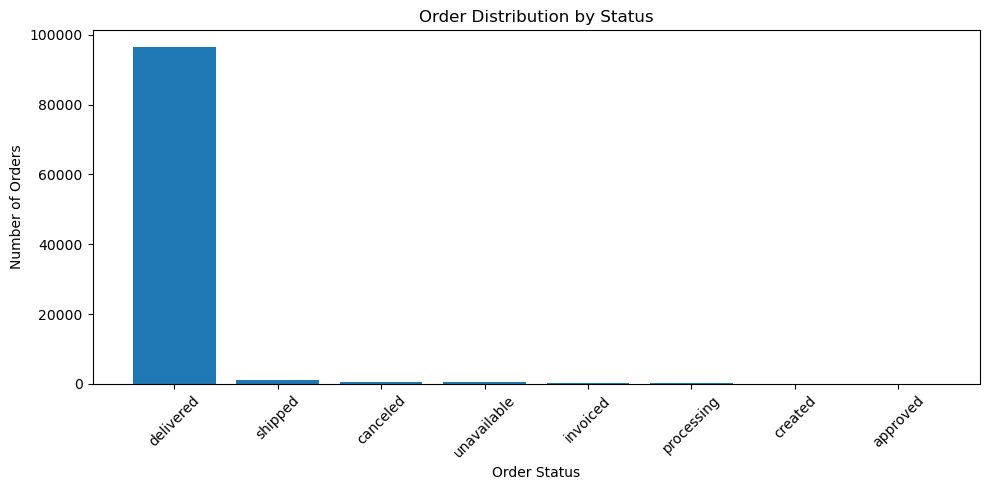

In [97]:
# Count orders by their current recorded status
status_summary = (
    Orders["order_status"]
    .value_counts(dropna=False)
    .rename_axis("Order Status")
    .reset_index(name="Order Count")
)

# Calculate each status as a percentage of all orders
status_summary["Percentage"] = (
    status_summary["Order Count"] / len(Orders) * 100
)

# Display the summary
display(status_summary)

# Plot order counts by status
plt.figure(figsize=(10, 5))

plt.bar(
    status_summary["Order Status"].astype(str),
    status_summary["Order Count"]
)

plt.title("Order Distribution by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,purchase_month,Order Count,Item Sales,Month
0,2016-09,4,267.36,2016-09-01
1,2016-10,324,49507.66,2016-10-01
2,2016-12,1,10.90,2016-12-01
3,2017-01,800,120312.87,2017-01-01
4,2017-02,1780,247303.02,2017-02-01
5,2017-03,2682,374344.30,2017-03-01
6,2017-04,2404,359927.23,2017-04-01
7,2017-05,3700,506071.14,2017-05-01
8,2017-06,3245,433038.60,2017-06-01
9,2017-07,4026,498031.48,2017-07-01


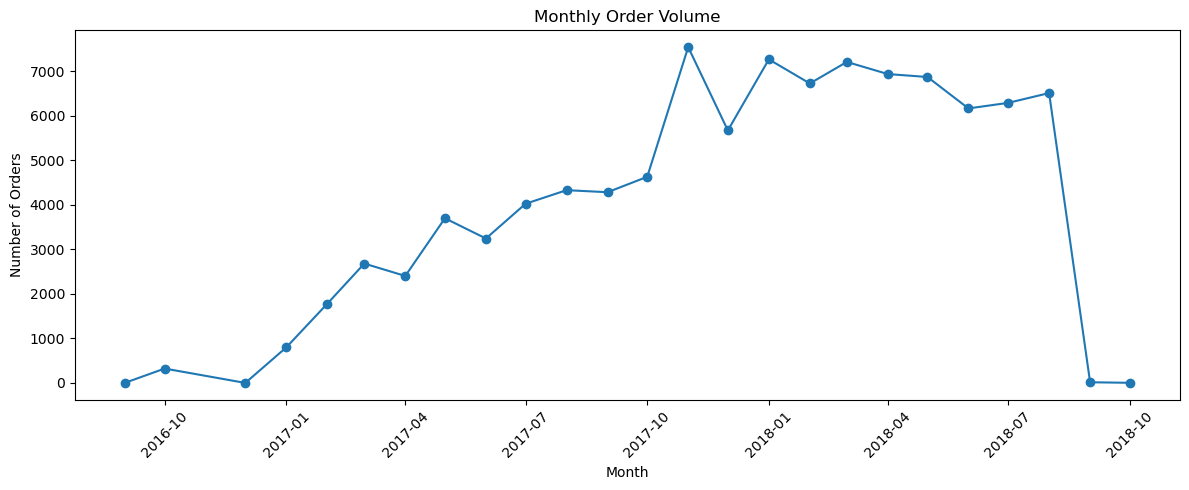

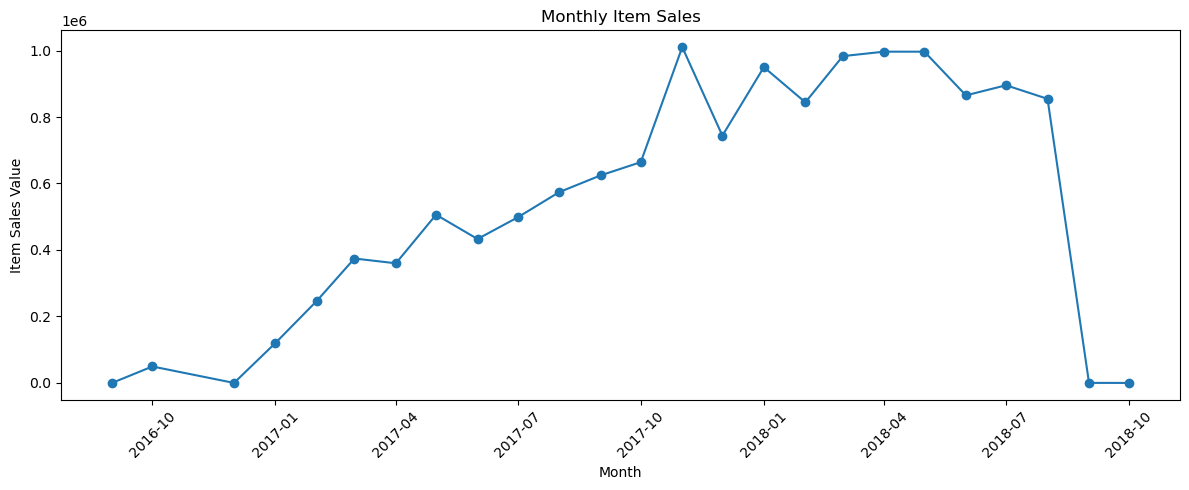

In [98]:
# Keep records with valid purchase timestamps
valid_orders = Orders[
    Orders["order_purchase_timestamp"].notna()
].copy()

# Extract the month of purchase
valid_orders["purchase_month"] = (
    valid_orders["order_purchase_timestamp"].dt.to_period("M")
)

# Count unique orders placed each month
monthly_orders = (
    valid_orders.groupby("purchase_month")["order_id"]
    .nunique()
    .rename("Order Count")
)

# Calculate item sales for each order
order_sales_df = Order_items.groupby("order_id")["price"].sum()

# Attach order dates to order sales
monthly_sales_data = valid_orders[
    ["order_id", "purchase_month"]
].merge(
    order_sales_df.rename("Item Sales"),
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Aggregate monthly item sales
monthly_sales = monthly_sales_data.groupby(
    "purchase_month"
)["Item Sales"].sum()

# Combine monthly orders and sales
monthly_summary = pd.concat(
    [monthly_orders, monthly_sales],
    axis=1
).reset_index()

# Convert the monthly period into a timestamp for plotting
monthly_summary["Month"] = (
    monthly_summary["purchase_month"].dt.to_timestamp()
)

display(monthly_summary)

# Plot monthly order volume
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_summary["Month"],
    monthly_summary["Order Count"],
    marker="o"
)

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot monthly item sales
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_summary["Month"],
    monthly_summary["Item Sales"],
    marker="o"
)

plt.title("Monthly Item Sales")
plt.xlabel("Month")
plt.ylabel("Item Sales Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Metric,Value
0,Unique Customers,96096.00
1,Customers with One Order,93099.00
2,Customers with Repeat Orders,2997.00
3,Repeat Customer Percentage,3.12


,customer_state,Order Count
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


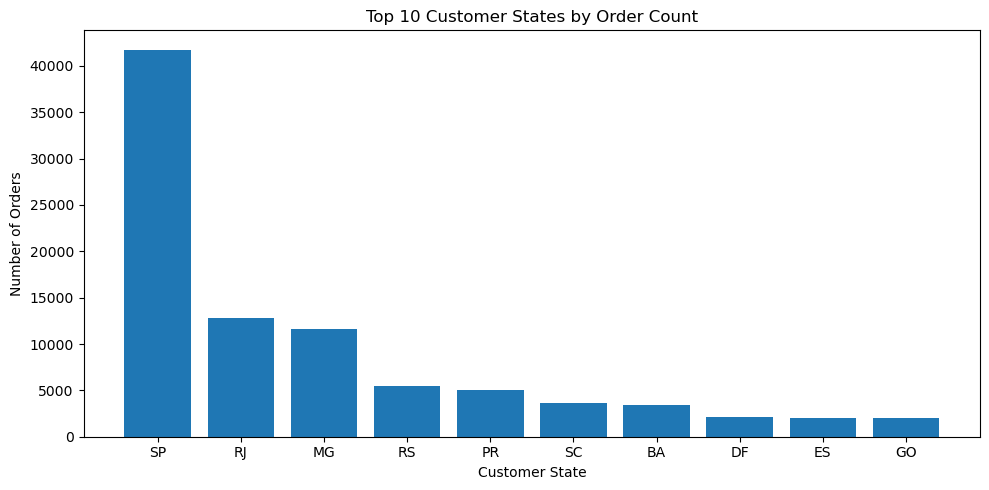

In [99]:
# Count orders placed by each customer
customer_order_counts = (
    orders_analysis.groupby("customer_unique_id")["order_id"]
    .nunique()
    .rename("Order Count")
)

# Calculate the number of customers with repeat orders
repeat_customers = (customer_order_counts > 1).sum()

# Calculate the number of customers with only one order
single_order_customers = (customer_order_counts == 1).sum()

# Calculate the percentage of repeat customers
repeat_customer_percentage = (
    repeat_customers / len(customer_order_counts) * 100
)

# Display customer purchase frequency
customer_summary = pd.DataFrame({
    "Metric": [
        "Unique Customers",
        "Customers with One Order",
        "Customers with Repeat Orders",
        "Repeat Customer Percentage"
    ],
    "Value": [
        len(customer_order_counts),
        single_order_customers,
        repeat_customers,
        repeat_customer_percentage
    ]
})

display(customer_summary)

# Analyze orders by customer state
customer_state_summary = (
    orders_analysis.groupby("customer_state")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="Order Count")
)

display(customer_state_summary.head(10))

# Plot the top 10 states by order count
top_states = customer_state_summary.head(10)

plt.figure(figsize=(10, 5))
plt.bar(
    top_states["customer_state"],
    top_states["Order Count"]
)

plt.title("Top 10 Customer States by Order Count")
plt.xlabel("Customer State")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

,product_category_name_english,Item_Sales,Items_Sold,Unique_Products
0,health_beauty,1258681.34,9670,2444
1,watches_gifts,1205005.68,5991,1329
2,bed_bath_table,1036988.68,11115,3029
3,sports_leisure,988048.97,8641,2867
4,computers_accessories,911954.32,7827,1639
5,furniture_decor,729762.49,8334,2657
6,cool_stuff,635290.85,3796,789
7,housewares,632248.66,6964,2335
8,auto,592720.11,4235,1900
9,garden_tools,485256.46,4347,753


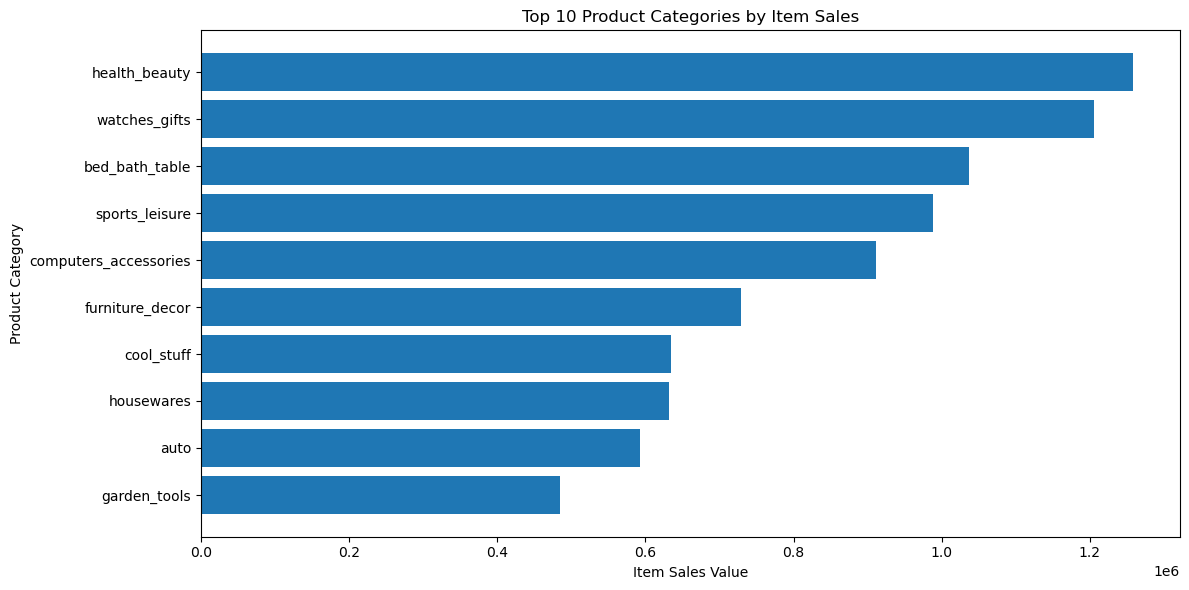

,product_category_name_english,Item_Sales,Items_Sold,Unique_Products
2,bed_bath_table,1036988.68,11115,3029
0,health_beauty,1258681.34,9670,2444
3,sports_leisure,988048.97,8641,2867
5,furniture_decor,729762.49,8334,2657
4,computers_accessories,911954.32,7827,1639
7,housewares,632248.66,6964,2335
1,watches_gifts,1205005.68,5991,1329
13,telephony,323667.53,4545,1134
9,garden_tools,485256.46,4347,753
8,auto,592720.11,4235,1900


In [100]:
# Identify the available English category column
category_column = "product_category_name_english"

# Calculate item sales by product category
category_sales = (
    sales_analysis.groupby(category_column, dropna=False)
    .agg(
        Item_Sales=("price", "sum"),
        Items_Sold=("order_item_id", "count"),
        Unique_Products=("product_id", "nunique")
    )
    .sort_values("Item_Sales", ascending=False)
    .reset_index()
)

# Display the top 10 categories by item sales
display(category_sales.head(10))

# Plot the top 10 categories by item sales
top_categories = category_sales.head(10)

plt.figure(figsize=(12, 6))
plt.barh(
    top_categories[category_column].fillna("Untranslated"),
    top_categories["Item_Sales"]
)

plt.title("Top 10 Product Categories by Item Sales")
plt.xlabel("Item Sales Value")
plt.ylabel("Product Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Identify the categories with the most items sold
top_categories_by_volume = category_sales.sort_values(
    "Items_Sold", ascending=False
).head(10)

display(top_categories_by_volume)

,payment_type,Payment_Records,Unique_Orders,Total_Payment_Value,Average_Payment_Value
0,credit_card,76795,76505,12542084.19,163.32
1,boleto,19784,19784,2869361.27,145.03
2,voucher,5775,3866,379436.87,65.70
3,debit_card,1529,1528,217989.79,142.57
4,not_defined,3,3,0.00,0.00


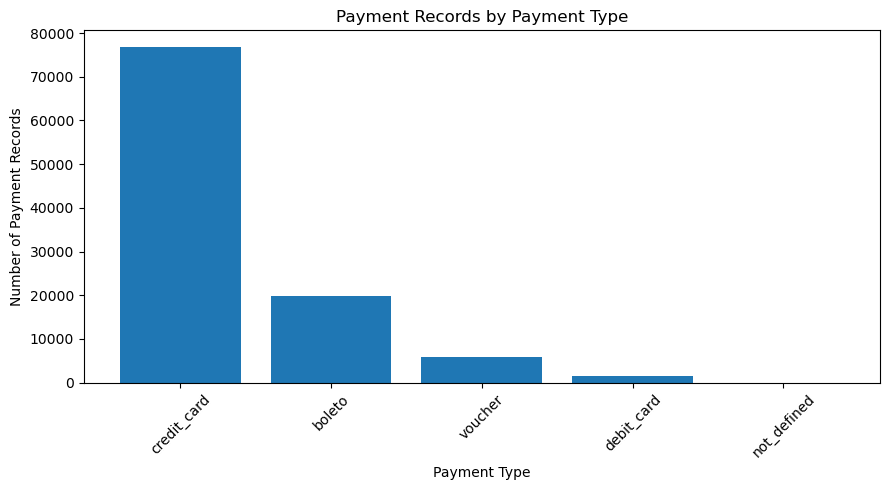

,payment_type,Payment_Records,Unique_Orders,Total_Payment_Value,Average_Payment_Value,Payment Value Percentage
0,credit_card,76795,76505,12542084.19,163.32,78.34
1,boleto,19784,19784,2869361.27,145.03,17.92
2,voucher,5775,3866,379436.87,65.70,2.37
3,debit_card,1529,1528,217989.79,142.57,1.36
4,not_defined,3,3,0.00,0.00,0.00


In [101]:
# Summarize payment methods by transaction count and value
payment_summary = (
    Order_Payment.groupby("payment_type", dropna=False)
    .agg(
        Payment_Records=("order_id", "size"),
        Unique_Orders=("order_id", "nunique"),
        Total_Payment_Value=("payment_value", "sum"),
        Average_Payment_Value=("payment_value", "mean")
    )
    .sort_values("Total_Payment_Value", ascending=False)
    .reset_index()
)

display(payment_summary)

# Plot the number of payment records by payment type
plt.figure(figsize=(9, 5))
plt.bar(
    payment_summary["payment_type"].astype(str),
    payment_summary["Payment_Records"]
)

plt.title("Payment Records by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Number of Payment Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate the share of payment value by payment method
payment_summary["Payment Value Percentage"] = (
    payment_summary["Total_Payment_Value"]
    / payment_summary["Total_Payment_Value"].sum() * 100
)

display(payment_summary)

,Delivery Performance,Order Count,Percentage
0,Early,88644,91.89
1,Late,6534,6.77
2,On Time,1292,1.34


Average delivery time (days): 12.56
Median delivery time (days): 10.22
Average delivery delay (days): -11.88


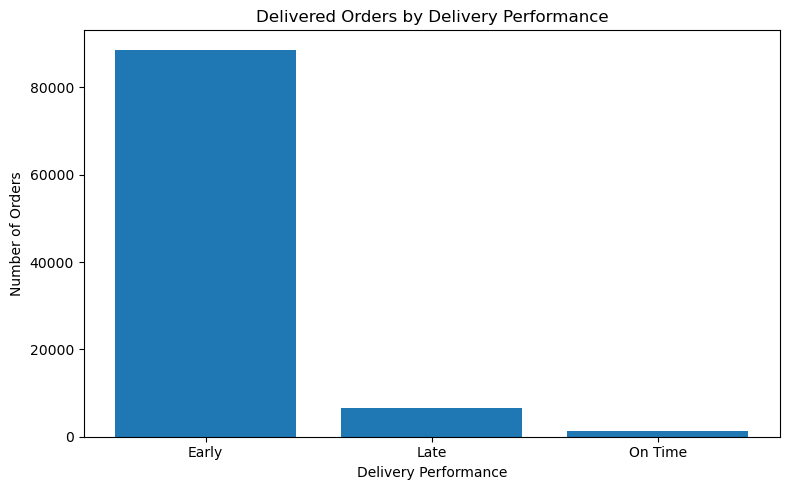

In [102]:
# Select delivered orders with actual and estimated delivery dates
delivery_data = Orders[
    (Orders["order_status"] == "delivered") &
    Orders["order_delivered_customer_date"].notna() &
    Orders["order_estimated_delivery_date"].notna()
].copy()

# Calculate delivery time in days
delivery_data["Actual Delivery Days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate delivery delay in days
# Positive means late; negative means early
delivery_data["Delivery Delay Days"] = (
    delivery_data["order_delivered_customer_date"].dt.normalize()
    - delivery_data["order_estimated_delivery_date"].dt.normalize()
).dt.total_seconds() / 86400

# Classify orders as early, on time, or late
delivery_data["Delivery Performance"] = np.select(
    [
        delivery_data["Delivery Delay Days"] > 0,
        delivery_data["Delivery Delay Days"] == 0
    ],
    [
        "Late",
        "On Time"
    ],
    default="Early"
)

# Summarize delivery performance
delivery_summary = (
    delivery_data["Delivery Performance"]
    .value_counts()
    .rename_axis("Delivery Performance")
    .reset_index(name="Order Count")
)

delivery_summary["Percentage"] = (
    delivery_summary["Order Count"]
    / delivery_summary["Order Count"].sum() * 100
)

display(delivery_summary)

# Calculate average delivery time and delay
print(
    "Average delivery time (days):",
    round(delivery_data["Actual Delivery Days"].mean(), 2)
)

print(
    "Median delivery time (days):",
    round(delivery_data["Actual Delivery Days"].median(), 2)
)

print(
    "Average delivery delay (days):",
    round(delivery_data["Delivery Delay Days"].mean(), 2)
)

# Plot delivery performance
plt.figure(figsize=(8, 5))
plt.bar(
    delivery_summary["Delivery Performance"],
    delivery_summary["Order Count"]
)

plt.title("Delivered Orders by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

,Review Score,Review Count,Percentage
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78


Average review score: 4.09


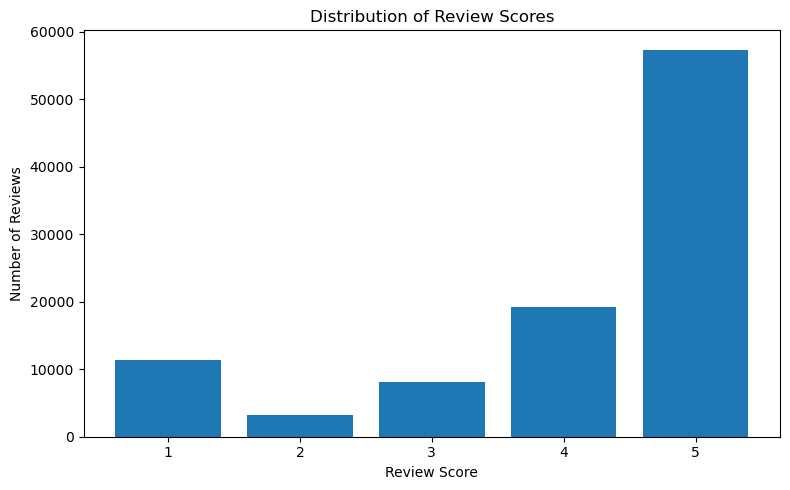

,order_status,count,mean,median
0,approved,2,2.50,2.50
1,canceled,609,1.81,1.00
2,created,3,2.33,1.00
3,delivered,96361,4.16,5.00
4,invoiced,313,1.66,1.00
5,processing,296,1.28,1.00
6,shipped,1043,2.01,1.00
7,unavailable,597,1.53,1.00


In [103]:
# Count each review score
review_score_summary = (
    Order_reviews["review_score"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Review Score")
    .reset_index(name="Review Count")
)

# Calculate the percentage for each score
review_score_summary["Percentage"] = (
    review_score_summary["Review Count"]
    / review_score_summary["Review Count"].sum() * 100
)

display(review_score_summary)

# Calculate the average review score
print(
    "Average review score:",
    round(Order_reviews["review_score"].mean(), 2)
)

# Plot review score distribution
plt.figure(figsize=(8, 5))
plt.bar(
    review_score_summary["Review Score"].astype(str),
    review_score_summary["Review Count"]
)

plt.title("Distribution of Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# Summarize review scores by order status
review_order_analysis = Order_reviews.merge(
    Orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

review_by_status = (
    review_order_analysis.groupby("order_status")["review_score"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

display(review_by_status)

,seller_id,Items_Sold,Unique_Orders,Unique_Products,Item_Sales,Freight_Charges
0,4869f7a5dfa277a7dca6462dcf3b52b2,1156,1132,95,229472.63,20168.07
1,53243585a1d6dc2643021fd1853d8905,410,358,23,222776.05,13080.63
2,4a3ca9315b744ce9f8e9374361493884,1987,1806,399,200472.92,35067.04
3,fa1c13f2614d7b5c4749cbc52fecda94,586,585,289,194042.03,10042.70
4,7c67e1448b00f6e969d365cea6b010ab,1364,982,198,187923.89,51612.55
5,7e93a43ef30c4f03f38b393420bc753a,340,336,186,176431.87,6322.18
6,da8622b14eb17ae2831f4ac5b9dab84a,1551,1314,222,160236.57,24955.75
7,7a67c85e85bb2ce8582c35f2203ad736,1171,1160,149,141745.53,20902.85
8,1025f0e2d44d7041d6cf58b6550e0bfa,1428,915,154,138968.55,33892.14
9,955fee9216a65b617aa5c0531780ce60,1499,1287,104,135171.70,25430.98


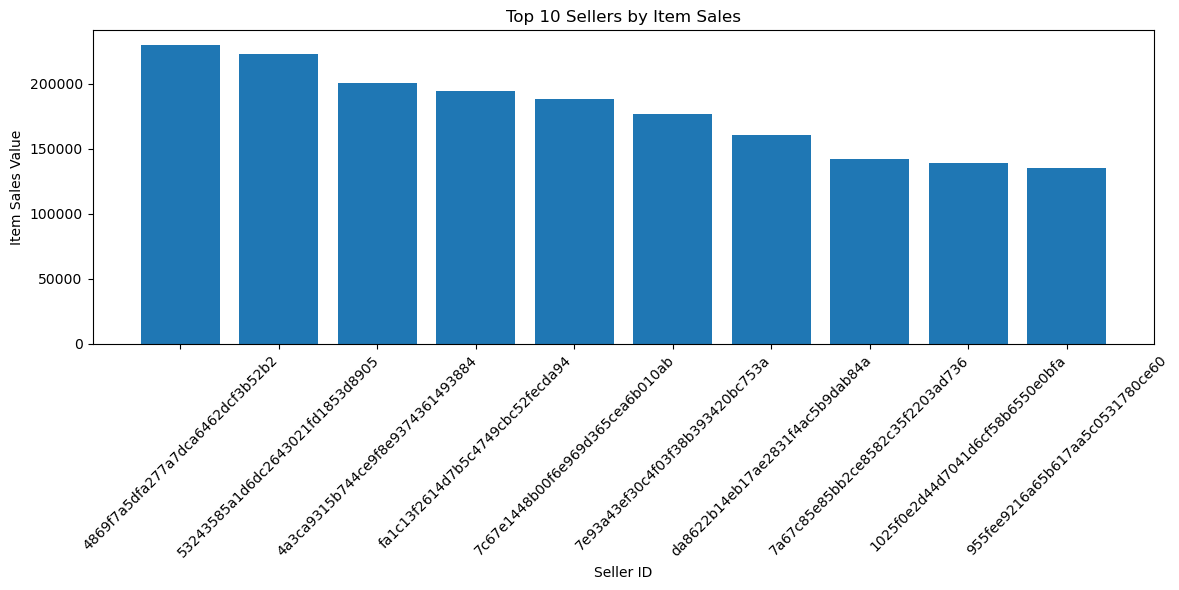

,seller_id,Items_Sold,Unique_Orders,Unique_Products,Item_Sales,Freight_Charges,Sales Share Percentage
0,4869f7a5dfa277a7dca6462dcf3b52b2,1156,1132,95,229472.63,20168.07,1.69
1,53243585a1d6dc2643021fd1853d8905,410,358,23,222776.05,13080.63,1.64
2,4a3ca9315b744ce9f8e9374361493884,1987,1806,399,200472.92,35067.04,1.47
3,fa1c13f2614d7b5c4749cbc52fecda94,586,585,289,194042.03,10042.70,1.43
4,7c67e1448b00f6e969d365cea6b010ab,1364,982,198,187923.89,51612.55,1.38
5,7e93a43ef30c4f03f38b393420bc753a,340,336,186,176431.87,6322.18,1.30
6,da8622b14eb17ae2831f4ac5b9dab84a,1551,1314,222,160236.57,24955.75,1.18
7,7a67c85e85bb2ce8582c35f2203ad736,1171,1160,149,141745.53,20902.85,1.04
8,1025f0e2d44d7041d6cf58b6550e0bfa,1428,915,154,138968.55,33892.14,1.02
9,955fee9216a65b617aa5c0531780ce60,1499,1287,104,135171.70,25430.98,0.99


In [104]:
# Summarize item sales and order activity by seller
seller_summary = (
    sales_analysis.groupby("seller_id")
    .agg(
        Items_Sold=("order_item_id", "count"),
        Unique_Orders=("order_id", "nunique"),
        Unique_Products=("product_id", "nunique"),
        Item_Sales=("price", "sum"),
        Freight_Charges=("freight_value", "sum")
    )
    .sort_values("Item_Sales", ascending=False)
    .reset_index()
)

# Display the top 10 sellers by item sales
display(seller_summary.head(10))

# Plot the top 10 sellers
top_sellers = seller_summary.head(10)

plt.figure(figsize=(12, 6))
plt.bar(
    top_sellers["seller_id"].astype(str),
    top_sellers["Item_Sales"]
)

plt.title("Top 10 Sellers by Item Sales")
plt.xlabel("Seller ID")
plt.ylabel("Item Sales Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate the percentage of total item sales for each seller
total_sales = seller_summary["Item_Sales"].sum()

seller_summary["Sales Share Percentage"] = (
    seller_summary["Item_Sales"] / total_sales * 100
)

display(seller_summary.head(10))

In [105]:
# Add customer state to delivery analysis
delivery_by_state = delivery_data.merge(
    Customer[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Calculate late-delivery rates by state
delivery_state_summary = (
    delivery_by_state.assign(
        Is_Late=delivery_by_state["Delivery Delay Days"] > 0
    )
    .groupby("customer_state")
    .agg(
        Delivered_Orders=("order_id", "nunique"),
        Late_Orders=("Is_Late", "sum"),
        Average_Delay_Days=("Delivery Delay Days", "mean")
    )
)

# Calculate late-delivery percentage
delivery_state_summary["Late Rate Percentage"] = (
    delivery_state_summary["Late_Orders"]
    / delivery_state_summary["Delivered_Orders"] * 100
)

# Show states with the most delivered orders
display(
    delivery_state_summary.sort_values(
        "Delivered_Orders", ascending=False
    ).head(10)
)

,Delivered_Orders,Late_Orders,Average_Delay_Days,Late Rate Percentage
customer_state,,,,
SP,40494,1820,-11.08,4.49
RJ,12350,1495,-11.76,12.11
MG,11354,519,-13.24,4.57
RS,5344,325,-13.91,6.08
PR,4923,199,-13.31,4.04
SC,3546,291,-11.50,8.21
BA,3256,396,-10.79,12.16
DF,2080,118,-12.05,5.67
ES,1995,214,-10.50,10.73


In [106]:
# Calculate one average review score per order
order_review_summary = (
    Order_reviews.groupby("order_id")["review_score"]
    .mean()
    .rename("Average Review Score")
    .reset_index()
)

# Attach review scores to delivery records
delivery_review_analysis = delivery_data.merge(
    order_review_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Compare average scores by delivery performance
review_delivery_summary = (
    delivery_review_analysis.groupby("Delivery Performance")
    .agg(
        Orders=("order_id", "nunique"),
        Average_Review_Score=("Average Review Score", "mean"),
        Median_Review_Score=("Average Review Score", "median")
    )
    .reset_index()
)

display(review_delivery_summary)

,Delivery Performance,Orders,Average_Review_Score,Median_Review_Score
0,Early,88644,4.29,5.00
1,Late,6534,2.27,1.00
2,On Time,1292,4.04,5.00


In [107]:
# Calculate the total recorded payment amount for each order
order_payment_totals = (
    Order_Payment.groupby("order_id")["payment_value"]
    .sum()
    .rename("Total Payment Value")
    .reset_index()
)

# Attach order statuses to payment totals
payment_order_analysis = order_payment_totals.merge(
    Orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Compare payment totals across order statuses
payment_status_summary = (
    payment_order_analysis.groupby("order_status")["Total Payment Value"]
    .agg(["count", "sum", "mean", "median"])
    .reset_index()
)

display(payment_status_summary)

,order_status,count,sum,mean,median
0,approved,2,241.08,120.54,120.54
1,canceled,625,143255.60,229.21,110.32
2,created,5,688.10,137.62,137.60
3,delivered,96477,15422461.77,159.86,105.28
4,invoiced,314,69137.99,220.18,137.77
5,processing,301,69394.11,230.55,144.56
6,shipped,1107,177213.96,160.08,103.39
7,unavailable,609,126479.51,207.68,104.63


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
product_name_lenght,1.00,0.10,0.13,0.04,0.08,-0.02,0.07
product_description_lenght,0.10,1.00,0.11,0.06,0.03,0.06,-0.03
product_photos_qty,0.13,0.11,1.00,0.04,0.07,0.00,0.03
product_weight_g,0.04,0.06,0.04,1.00,0.48,0.56,0.53
product_length_cm,0.08,0.03,0.07,0.48,1.00,0.20,0.54
product_height_cm,-0.02,0.06,0.00,0.56,0.20,1.00,0.31
product_width_cm,0.07,-0.03,0.03,0.53,0.54,0.31,1.00


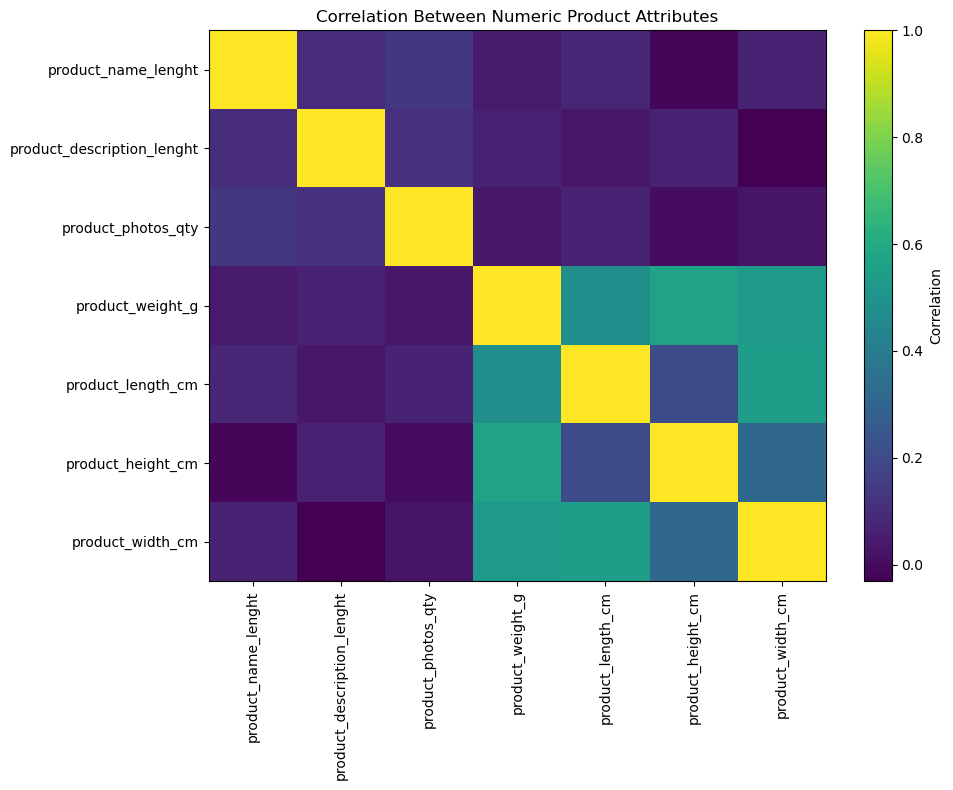

In [108]:
# Select numeric product attributes for correlation analysis
numeric_product_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

# Calculate the correlation matrix
product_correlation = Products[numeric_product_columns].corr()

display(product_correlation)

# Visualize the correlation matrix
plt.figure(figsize=(10, 8))

plt.imshow(product_correlation, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numeric_product_columns)),
    numeric_product_columns,
    rotation=90
)

plt.yticks(
    range(len(numeric_product_columns)),
    numeric_product_columns
)

plt.title("Correlation Between Numeric Product Attributes")
plt.tight_layout()
plt.show()

In [109]:
# Create a concise summary of major business metrics
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Unique Customers",
        "Unique Products",
        "Unique Sellers",
        "Total Item Sales",
        "Total Freight Charges",
        "Average Item Price",
        "Average Item Sales per Order",
        "Average Review Score",
        "Delivered Orders",
        "Late Delivered Orders"
    ],
    "Value": [
        Orders["order_id"].nunique(),
        Customer["customer_unique_id"].nunique(),
        Products["product_id"].nunique(),
        Sellers["seller_id"].nunique(),
        Order_items["price"].sum(),
        Order_items["freight_value"].sum(),
        Order_items["price"].mean(),
        Order_items.groupby("order_id")["price"].sum().mean(),
        Order_reviews["review_score"].mean(),
        len(delivery_data),
        (delivery_data["Delivery Delay Days"] > 0).sum()
    ]
})

display(eda_summary)

,Metric,Value
0,Total Orders,99441.00
1,Unique Customers,96096.00
2,Unique Products,32951.00
3,Unique Sellers,3095.00
4,Total Item Sales,13591643.70
5,Total Freight Charges,2251909.54
6,Average Item Price,120.65
7,Average Item Sales per Order,137.75
8,Average Review Score,4.09
9,Delivered Orders,96470.00
